In [ ]:
from langchain_groq import ChatGroq
from dotenv import load_dotenv
import os

In [ ]:
load_dotenv()

model = os.getenv('GROQ_MODEL')
api_key = os.getenv('GROQ_API_KEY')

In [ ]:
llm = ChatGroq(model=model, api_key=api_key)

In [ ]:
from pydantic import BaseModel
from langgraph.graph import START, END, StateGraph

In [ ]:
class State(BaseModel):
    title:str = ""
    story:str = ""

In [ ]:
def write_story(state:State):
    """Using LLM to write a short story on title"""
    res = llm.invoke(f"Write a short 10 - 15 words story on title: {state.title}")
    state.story = res.content

    return state

In [ ]:
graph = StateGraph(State)
graph.add_node("story_node",write_story)

graph.add_edge(START, "story_node")
graph.add_edge("story_node", END)

app = graph.compile()

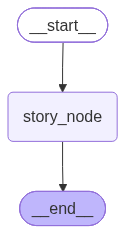

In [ ]:
app

In [ ]:
res = app.invoke({"title":"Sky is Blue"})
res['story']

'**Sky is Blue**\n\nShe looked up, finding hope reflected in the endless, calm blue sky.'